1. Telecom Customer Churn Analysis
This project analyzes customer churn patterns and identifies factors associated with customer cancellations.


In [9]:
import pandas as pd
import numpy as np

print("Hello, Telecom Churn Project!")

Hello, Telecom Churn Project!


## 2. Load the Dataset

In this step, we load the telecom customer dataset into a Pandas DataFrame. We will inspect the records to understand the structure of the data before performing data cleaning and analysis.

In [11]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("\nFiles in the data folder:")

data_folder = Path("../data")

if data_folder.exists():
    for file in data_folder.iterdir():
        print(file.name)
else:
    print("Data folder not found at:", data_folder.resolve())

Current folder: c:\Users\hp\OneDrive\Desktop\telecom -churn-predictioin\notebooks

Files in the data folder:
datacode.py
WA_Fn-UseC_-Telco-Customer-Churn (1).csv


load the data set


In [12]:
import pandas as pd

df = pd.read_csv(
    "../data/WA_Fn-UseC_-Telco-Customer-Churn (1).csv"
)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Check data quality


In [13]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

Step 2 — Check missing values and customer churn

In [14]:
# 1. Check dataset size
print("Dataset shape:", df.shape)

# 2. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Count customers who churned
print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset shape: (7043, 21)

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


Step 3 — Clean TotalCharges

In [15]:
# Check the TotalCharges column
print("TotalCharges data type before cleaning:")
print(df["TotalCharges"].dtype)

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("\nMissing TotalCharges after conversion:")
print(df["TotalCharges"].isnull().sum())

# Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"]).copy()

print("\nDataset shape after cleaning:", df.shape)

# Check the updated data types
print("\nUpdated TotalCharges data type:")
print(df["TotalCharges"].dtype)

TotalCharges data type before cleaning:
str

Missing TotalCharges after conversion:
11

Dataset shape after cleaning: (7032, 21)

Updated TotalCharges data type:
float64


Step 4 — Calculate the churn rate

In [16]:
# Count customers who stayed and left
churn_counts = df["Churn"].value_counts()

# Calculate total customers
total_customers = len(df)

# Calculate customers who churned
churned_customers = churn_counts["Yes"]

# Calculate churn rate
churn_rate = (churned_customers / total_customers) * 100

print("Total customers:", total_customers)
print("Customers who churned:", churned_customers)
print("Customers who stayed:", churn_counts["No"])
print(f"Overall churn rate: {churn_rate:.2f}%")

Total customers: 7032
Customers who churned: 1869
Customers who stayed: 5163
Overall churn rate: 26.58%


Step 5 — Visualize customer churn

In [19]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)

   ------------- -------------------------- 1/3 [contourpy]
   -------------------------- ------------- 2/3 [matplotlib]
   -------------------------- ------------- 2/3 [matplotlib]
   -------------------------- ------------- 2/3 [matplotlib]
   -------------------------- ------------- 2/3 [matplotlib]
   -------------------------- ------------- 2/3 [matplotlib]
   -------------------------- ------------- 2/3 [matplotlib]
   -------------------------- ------------- 2/3 [matplotlib]
   -------------------------- ------------- 2/3 [matplotlib]
   -------------------------- ------------- 2/3 [matp


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


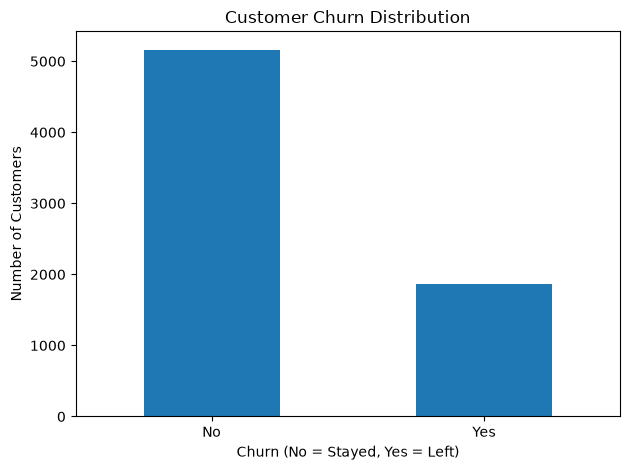

In [20]:
import matplotlib.pyplot as plt

churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])

churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (No = Stayed, Yes = Left)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Step 6 — Churn rate by contract type

In [21]:
# Calculate churn rate for each contract type
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("Churn rate by contract type:")
print(contract_churn)

Churn rate by contract type:
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64


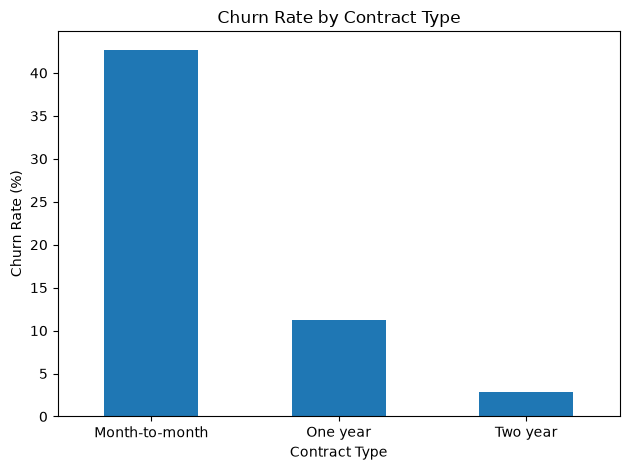

In [22]:
#visualize the results
import matplotlib.pyplot as plt

contract_churn.plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Step 7 — Which customers leave more often?

In [23]:
# Create tenure groups
def tenure_group(months):
    if months <= 12:
        return "0-12 months"
    elif months <= 24:
        return "13-24 months"
    elif months <= 48:
        return "25-48 months"
    else:
        return "49-72 months"

df["TenureGroup"] = df["tenure"].apply(tenure_group)

# Calculate churn rate for each tenure group
tenure_churn = (
    df.groupby("TenureGroup")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

# Display groups in the correct order
tenure_churn = tenure_churn.reindex([
    "0-12 months",
    "13-24 months",
    "25-48 months",
    "49-72 months"
])

print("Churn rate by customer tenure:")
print(tenure_churn)

Churn rate by customer tenure:
TenureGroup
0-12 months     47.68
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64


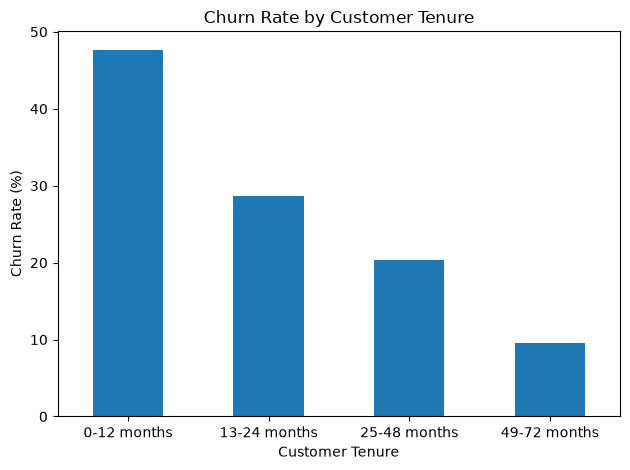

In [24]:
tenure_churn.plot(kind="bar")

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Step 8.1 — Calculate churn rate by payment method

In [25]:
# Calculate churn rate by payment method
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("Churn rate by payment method:")
print(payment_churn)

Churn rate by payment method:
PaymentMethod
Electronic check             45.29
Mailed check                 19.20
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Name: Churn, dtype: float64


In [27]:
print("Payment method column:")
print(df["PaymentMethod"].head())

print("\nUnique payment methods:")
print(df["PaymentMethod"].unique())

print("\nChurn values:")
print(df["Churn"].unique())

Payment method column:
0             Electronic check
1                 Mailed check
2                 Mailed check
3    Bank transfer (automatic)
4             Electronic check
Name: PaymentMethod, dtype: str

Unique payment methods:
<StringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str

Churn values:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [28]:
payment_churn = df.groupby("PaymentMethod").apply(
    lambda group: (group["Churn"] == "Yes").mean() * 100
)

print(payment_churn.round(2))

PaymentMethod
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Electronic check             45.29
Mailed check                 19.20
dtype: float64


Step 9 — Analyze monthly charges

In [29]:
# Compare monthly charges for customers who stayed and left
monthly_charges = df.groupby("Churn")["MonthlyCharges"].mean()

print("Average monthly charges by churn status:")
print(monthly_charges.round(2))

Average monthly charges by churn status:
Churn
No     61.31
Yes    74.44
Name: MonthlyCharges, dtype: float64


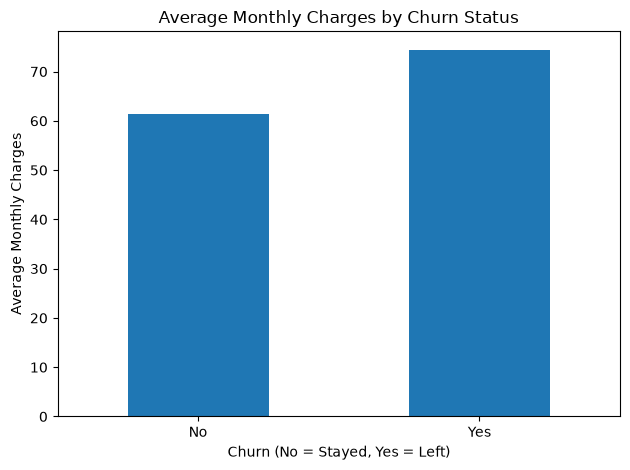

In [30]:
monthly_charges.plot(kind="bar")

plt.title("Average Monthly Charges by Churn Status")
plt.xlabel("Churn (No = Stayed, Yes = Left)")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Step 10.1 — Calculate average total charges

In [31]:
# Compare average total charges by churn status
total_charges = df.groupby("Churn")["TotalCharges"].mean()

print("Average total charges by churn status:")
print(total_charges.round(2))

Average total charges by churn status:
Churn
No     2555.34
Yes    1531.80
Name: TotalCharges, dtype: float64


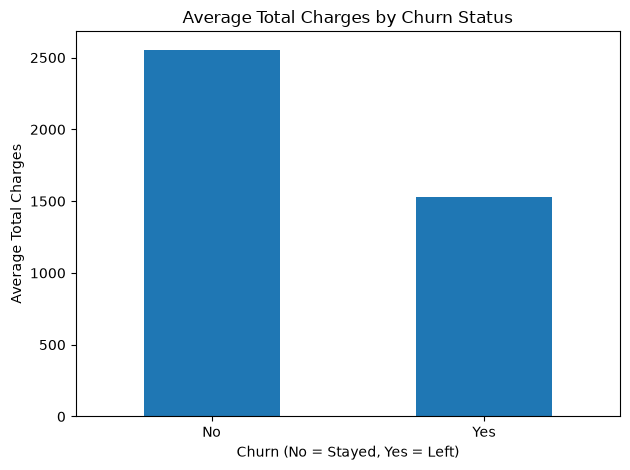

In [32]:
total_charges.plot(kind="bar")

plt.title("Average Total Charges by Churn Status")
plt.xlabel("Churn (No = Stayed, Yes = Left)")
plt.ylabel("Average Total Charges")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Step 11 — Create your EDA summary

In [33]:
# Summarize the main churn findings

overall_churn = (df["Churn"] == "Yes").mean() * 100

contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

tenure_churn = (
    df.groupby("TenureGroup")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print(f"Total customers analyzed: {len(df)}")
print(f"Overall churn rate: {overall_churn:.2f}%")

print("\nChurn rate by contract:")
print(contract_churn.round(2).sort_values(ascending=False))

print("\nChurn rate by tenure:")
print(tenure_churn.round(2))

print("\nChurn rate by payment method:")
print(payment_churn.round(2).sort_values(ascending=False))

Total customers analyzed: 7032
Overall churn rate: 26.58%

Churn rate by contract:
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64

Churn rate by tenure:
TenureGroup
0-12 months     47.68
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64

Churn rate by payment method:
PaymentMethod
Electronic check             45.29
Mailed check                 19.20
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Name: Churn, dtype: float64


Step 12 — Separate input features and target

In [34]:
# Separate the target column from input features

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFirst five input rows:")
display(X.head())

Input features shape: (7032, 20)
Target shape: (7032,)

Target distribution:
Churn
0    5163
1    1869
Name: count, dtype: int64

First five input rows:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,TenureGroup
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0-12 months
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,25-48 months
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,0-12 months
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,25-48 months
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,0-12 months


Step 13 — Split the data into training and testing sets

In [37]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training rows: 5625
Testing rows: 1407

Training churn rate: 26.58 %
Testing churn rate: 26.58 %


Step 14 — Prepare the data for the Random Forest model

In [40]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Prepare numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nNumerical columns:", numeric_features)
print("\nCategorical columns:", categorical_features)

Numerical features: 4
Categorical features: 16

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


C:\Users\hp\AppData\Local\Temp\ipykernel_9284\586349488.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


Step 15.1 — Train the model

In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the complete machine learning pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [42]:
# Predict churn on unseen test data
y_pred = model.predict(X_test)

print("Predictions completed!")
print("\nFirst 10 actual values:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())

Predictions completed!

First 10 actual values:
[0, 0, 0, 1, 0, 1, 0, 0, 1, 0]

First 10 predicted values:
[0, 1, 0, 0, 0, 0, 0, 0, 1, 0]


In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.2%}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.2%}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.2%}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.2%}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

Accuracy:  76.12%
Precision: 54.26%
Recall:    64.71%
F1-score:  59.02%

Detailed classification report:
              precision    recall  f1-score   support

      Stayed       0.86      0.80      0.83      1033
     Churned       0.54      0.65      0.59       374

    accuracy                           0.76      1407
   macro avg       0.70      0.72      0.71      1407
weighted avg       0.78      0.76      0.77      1407



Step 16 — Create a confusion matrix

Confusion Matrix:
[[829 204]
 [132 242]]


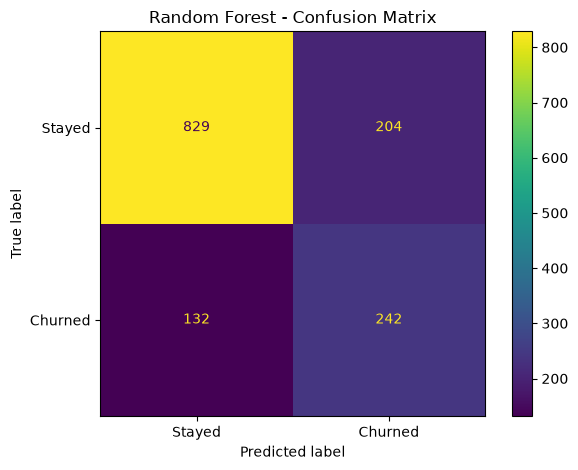

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compare actual and predicted churn
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize the results
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

display_matrix.plot()
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

Step 17 — Find the most important features

In [45]:
# Get transformed feature names
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Random Forest feature importance scores
importance = model.named_steps[
    "classifier"
].feature_importances_

# Create a sorted table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 important features:")
display(feature_importance.head(10))

Top 10 important features:


,Feature,Importance
3,num__TotalCharges,0.128827
2,num__MonthlyCharges,0.118721
1,num__tenure,0.114195
36,cat__Contract_Month-to-month,0.077259
18,cat__OnlineSecurity_No,0.038268
27,cat__TechSupport_No,0.030922
43,cat__PaymentMethod_Electronic check,0.030160
16,cat__InternetService_Fiber optic,0.027599
38,cat__Contract_Two year,0.027180
45,cat__TenureGroup_0-12 months,0.023568


Step 18.1 — Create a model performance table

In [46]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Create a performance summary from your actual test predictions
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score (%)": [
        accuracy_score(y_test, y_pred) * 100,
        precision_score(y_test, y_pred, zero_division=0) * 100,
        recall_score(y_test, y_pred, zero_division=0) * 100,
        f1_score(y_test, y_pred, zero_division=0) * 100
    ]
})

results["Score (%)"] = results["Score (%)"].round(2)

display(results)

,Metric,Score (%)
0,Accuracy,76.12
1,Precision,54.26
2,Recall,64.71
3,F1-score,59.02


In [47]:
print("OVERALL CHURN RATE")
print(f"{(df['Churn'] == 'Yes').mean() * 100:.2f}%")

print("\nCHURN RATE BY CONTRACT")
display(
    (df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
       .groupby("Contract")["ChurnFlag"]
       .mean()
       .mul(100)
       .round(2)
       .sort_values(ascending=False))
)

print("\nCHURN RATE BY PAYMENT METHOD")
display(payment_churn.round(2))

OVERALL CHURN RATE
26.58%

CHURN RATE BY CONTRACT


Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: ChurnFlag, dtype: float64


CHURN RATE BY PAYMENT METHOD


PaymentMethod
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Electronic check             45.29
Mailed check                 19.20
Name: Churn, dtype: float64

Step 20 — Identify high-risk customer groups

In [48]:
# Calculate churn rate by contract
contract_summary = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
    .groupby("Contract")
    .agg(
        Total_Customers=("ChurnFlag", "size"),
        Churned_Customers=("ChurnFlag", "sum"),
        Churn_Rate=("ChurnFlag", "mean")
    )
)

contract_summary["Churn_Rate"] = (
    contract_summary["Churn_Rate"] * 100
).round(2)

contract_summary = contract_summary.sort_values(
    "Churn_Rate", ascending=False
)

display(contract_summary)

,Total_Customers,Churned_Customers,Churn_Rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1472,166,11.28
Two year,1685,48,2.85


Step 21 — Turn the findings into business recommendations
Use the actual table output to guide your recommendations:
Finding to verify	Possible business action
Month-to-month contracts have higher churn	Offer suitable longer-term plans or loyalty benefits
New customers have higher churn	Improve onboarding and early customer support
Electronic Check users have higher churn	Investigate payment experience and offer convenient alternatives

Step 22 — Find the top 10 customers most likely to churn

In [49]:
# Predict the probability of churn for test customers
churn_probabilities = model.predict_proba(X_test)[:, 1]

# Create a table of churn risk
risk_table = X_test.copy()

risk_table["Actual_Churn"] = y_test.values
risk_table["Churn_Probability"] = churn_probabilities
risk_table["Churn_Risk_Percent"] = (
    risk_table["Churn_Probability"] * 100
).round(2)

# Sort customers from highest to lowest predicted risk
risk_table = risk_table.sort_values(
    by="Churn_Probability",
    ascending=False
)

print("Top 10 customers with the highest predicted churn risk:")
display(risk_table.head(10))

Top 10 customers with the highest predicted churn risk:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,TenureGroup,Actual_Churn,Churn_Probability,Churn_Risk_Percent
3682,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,69.10,69.10,0-12 months,1,1.000,100.0
1739,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,69.90,69.90,0-12 months,1,1.000,100.0
684,Female,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,No,Mailed check,71.10,71.10,0-12 months,0,1.000,100.0
3727,Female,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,96.60,291.90,0-12 months,1,1.000,100.0
1731,Female,1,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,69.60,69.60,0-12 months,1,1.000,100.0
2927,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,69.90,69.90,0-12 months,0,1.000,100.0
532,Male,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,79.95,174.45,0-12 months,0,0.995,99.5
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,0-12 months,1,0.995,99.5
1144,Male,0,No,No,1,No,No phone service,DSL,No,No,...,Yes,Month-to-month,Yes,Electronic check,35.55,35.55,0-12 months,1,0.995,99.5
5098,Male,1,No,No,3,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,77.00,237.75,0-12 months,1,0.995,99.5


Step 23 — Save the model

In [50]:
import joblib

joblib.dump(model, "../telecom_churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


Step 24 — Check your project files

In [52]:
from pathlib import Path

project_folder = Path("..")

print("Project files and folders:\n")

for item in sorted(project_folder.iterdir()):
    if item.name != ".venv" and item.name != ".git":
        print(item.name)

Project files and folders:

dashboard
data
notebooks
telecom_churn_model.pkl


Step 25 — Create requirements.txt

In [53]:
packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "joblib"
]

Path("../requirements.txt").write_text(
    "\n".join(packages) + "\n",
    encoding="utf-8"
)

print("requirements.txt created successfully!")

requirements.txt created successfully!


Step 26 — Check your project files again

In [54]:
from pathlib import Path

project_folder = Path("..")

for folder in ["notebooks", "data", "dashboard"]:
    path = project_folder / folder
    print(f"\n{folder}/")

    if path.exists():
        for item in sorted(path.iterdir()):
            print("  ", item.name)

print("\nRoot files:")
for item in sorted(project_folder.iterdir()):
    if item.is_file():
        print("  ", item.name)


notebooks/
   01_churn_eda.ipynb

data/
   datacode.py
   WA_Fn-UseC_-Telco-Customer-Churn (1).csv

dashboard/

Root files:
   requirements.txt
   telecom_churn_model.pkl


Step 28.1 — Check your model metrics

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score (%)": [
        accuracy_score(y_test, y_pred) * 100,
        precision_score(y_test, y_pred, zero_division=0) * 100,
        recall_score(y_test, y_pred, zero_division=0) * 100,
        f1_score(y_test, y_pred, zero_division=0) * 100
    ]
})

results["Score (%)"] = results["Score (%)"].round(2)

display(results)

,Metric,Score (%)
0,Accuracy,76.12
1,Precision,54.26
2,Recall,64.71
3,F1-score,59.02


In [56]:
results.to_csv("../model_performance.csv", index=False)

print("Model performance saved successfully!")

Model performance saved successfully!


Step 29.1 — Load the saved model

In [57]:
import joblib
from pathlib import Path

model_path = Path("../telecom_churn_model.pkl")

loaded_model = joblib.load(model_path)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [58]:
# Predict churn using the saved model
loaded_predictions = loaded_model.predict(X_test)

print("First 10 predictions:")
print(loaded_predictions[:10])

print("\nPredictions completed successfully!")

First 10 predictions:
[0 1 0 0 0 0 0 0 1 0]

Predictions completed successfully!


In [59]:
from sklearn.metrics import accuracy_score

loaded_accuracy = accuracy_score(y_test, loaded_predictions)

print(f"Accuracy of loaded model: {loaded_accuracy:.2%}")

Accuracy of loaded model: 76.12%


Step 30.1 — Create a sample customer

In [62]:
import pandas as pd

new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 75.00,
    "TotalCharges": 150.00
}])

# Add the feature that was created during EDA
new_customer["TenureGroup"] = "0-12 months"

print("Customer profile prepared successfully!")
print("Number of features:", new_customer.shape[1])

Customer profile prepared successfully!
Number of features: 20


In [63]:
prediction = loaded_model.predict(new_customer)[0]
churn_probability = loaded_model.predict_proba(new_customer)[0][1]

print(
    "Predicted outcome:",
    "Likely to churn" if prediction == 1 else "Likely to stay"
)

print(f"Estimated churn probability: {churn_probability:.2%}")

Predicted outcome: Likely to churn
Estimated churn probability: 87.50%


Check your model performance

In [64]:
import pandas as pd

results = pd.read_csv("../model_performance.csv")
display(results)

,Metric,Score (%)
0,Accuracy,76.12
1,Precision,54.26
2,Recall,64.71
3,F1-score,59.02


Generate a confusion matrix

array([[829, 204],
       [132, 242]])

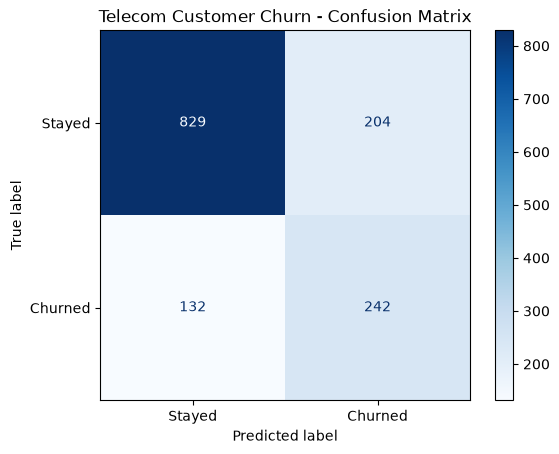

In [65]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
).plot(cmap="Blues")

plt.title("Telecom Customer Churn - Confusion Matrix")
plt.show()

In [66]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives (Correctly predicted Stayed):", tn)
print("False Positives (Predicted Churn, but Stayed):", fp)
print("False Negatives (Predicted Stayed, but Churned):", fn)
print("True Positives (Correctly predicted Churned):", tp)

Confusion Matrix:
[[829 204]
 [132 242]]

True Negatives (Correctly predicted Stayed): 829
False Positives (Predicted Churn, but Stayed): 204
False Negatives (Predicted Stayed, but Churned): 132
True Positives (Correctly predicted Churned): 242


Random Forest model

In [67]:
import pandas as pd

feature_names = (
    model.named_steps["preprocessor"].get_feature_names_out()
)

importances = model.named_steps["classifier"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

display(feature_importance.head(10))

,Feature,Importance
3,num__TotalCharges,0.128827
2,num__MonthlyCharges,0.118721
1,num__tenure,0.114195
36,cat__Contract_Month-to-month,0.077259
18,cat__OnlineSecurity_No,0.038268
27,cat__TechSupport_No,0.030922
43,cat__PaymentMethod_Electronic check,0.030160
16,cat__InternetService_Fiber optic,0.027599
38,cat__Contract_Two year,0.027180
45,cat__TenureGroup_0-12 months,0.023568


Top 10 Feature Importance 

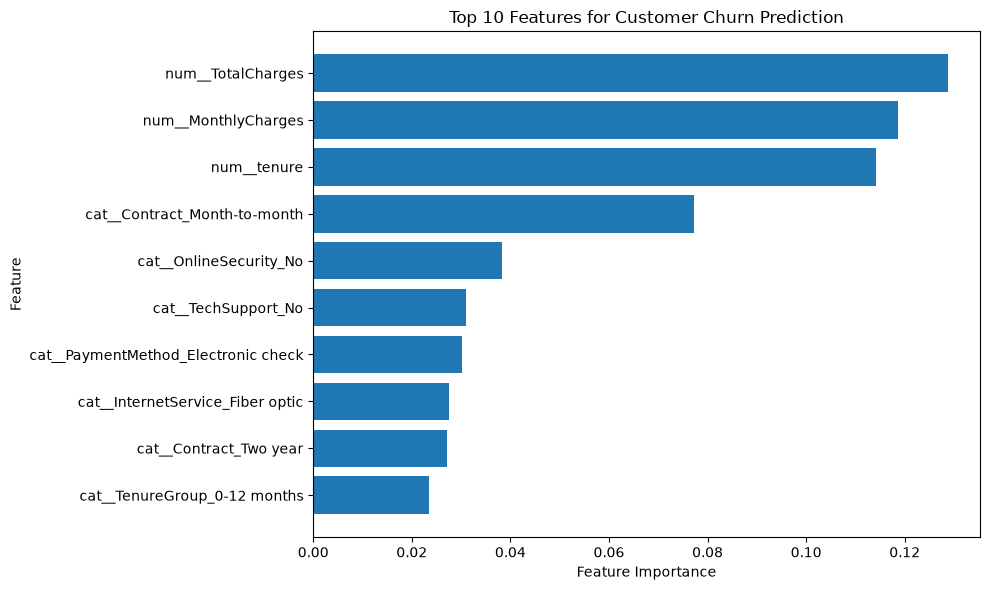

In [68]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features for Customer Churn Prediction")
plt.tight_layout()
plt.show()

In [69]:
print("TELECOM CUSTOMER CHURN: BUSINESS INSIGHTS")
print("-" * 45)

print("1. Overall churn rate:")
print(f"{(y == 1).mean() * 100:.2f}%")

print("\n2. Churn rate by contract:")
print(
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("\n3. Churn rate by tenure group:")
print(
    df.groupby("TenureGroup")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print("\n4. Churn rate by payment method:")
print(
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

TELECOM CUSTOMER CHURN: BUSINESS INSIGHTS
---------------------------------------------
1. Overall churn rate:
26.58%

2. Churn rate by contract:
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64

3. Churn rate by tenure group:
TenureGroup
0-12 months     47.68
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64

4. Churn rate by payment method:
PaymentMethod
Electronic check             45.29
Mailed check                 19.20
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Name: Churn, dtype: float64


In [70]:
import pandas as pd

# Overall churn rate
overall_churn = (y == 1).mean() * 100

# Churn rates by category
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

tenure_churn = (
    df.groupby("TenureGroup")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Combine findings into one report
insights = pd.DataFrame([
    {"Category": "Overall", "Segment": "All Customers",
     "Churn Rate (%)": round(overall_churn, 2)}
] + [
    {"Category": "Contract", "Segment": k,
     "Churn Rate (%)": round(v, 2)}
    for k, v in contract_churn.items()
] + [
    {"Category": "Tenure", "Segment": k,
     "Churn Rate (%)": round(v, 2)}
    for k, v in tenure_churn.items()
] + [
    {"Category": "Payment Method", "Segment": k,
     "Churn Rate (%)": round(v, 2)}
    for k, v in payment_churn.items()
])

insights.to_csv("../business_insights.csv", index=False)

print("Business insights saved successfully!")
display(insights)

Business insights saved successfully!


,Category,Segment,Churn Rate (%)
0,Overall,All Customers,26.58
1,Contract,Month-to-month,42.71
2,Contract,One year,11.28
3,Contract,Two year,2.85
4,Tenure,0-12 months,47.68
5,Tenure,13-24 months,28.71
6,Tenure,25-48 months,20.39
7,Tenure,49-72 months,9.51
8,Payment Method,Bank transfer (automatic),16.73
9,Payment Method,Credit card (automatic),15.25


In [71]:
# Export the cleaned dataset for Power BI
df.to_csv("../telecom_churn_cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")
print("Dataset shape:", df.shape)
print("Saved as: telecom_churn_cleaned.csv")

Cleaned dataset exported successfully!
Dataset shape: (7032, 22)
Saved as: telecom_churn_cleaned.csv
